In [1]:
!pip install segmentation-models-pytorch albumentations -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 4.1 MB/s eta 0:00:00


### **Data Pipeline Initialization**

Builds a custom PyTorch `Dataset`, applies **Albumentations** normalization, and initializes a batched `DataLoader`.

In [2]:
import os
import cv2
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2

class ISIC2018Dataset(Dataset):
    def __init__(self, image_dir, mask_dir, transform=None):
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.transform = transform
        
        # Get all image filenames, ignoring Kaggle's hidden files
        self.images = [img for img in os.listdir(image_dir) if img.endswith('.jpg')]
        
    def __len__(self):
        return len(self.images)
    
    def __getitem__(self, idx):
        img_name = self.images[idx]
        mask_name = img_name.replace('.jpg', '_segmentation.png')
        
        img_path = os.path.join(self.image_dir, img_name)
        mask_path = os.path.join(self.mask_dir, mask_name)
        
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB) 
        
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        mask = (mask > 127).astype(np.float32)
        
        if self.transform is not None:
            augmentations = self.transform(image=image, mask=mask)
            image = augmentations["image"]
            mask = augmentations["mask"]
            
        mask = torch.unsqueeze(mask, 0)
        return image, mask

def get_transforms():
    return A.Compose([
        A.Resize(height=256, width=256),
        A.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225],
            max_pixel_value=255.0,
        ),
        ToTensorV2(),
    ])

# Dynamically find the exact Kaggle dataset folder name
import os

dataset_root = "/kaggle/input/datasets/tschandl/isic2018-challenge-task1-data-segmentation"
img_dir = f"{dataset_root}/ISIC2018_Task1-2_Training_Input"
mask_dir = f"{dataset_root}/ISIC2018_Task1_Training_GroundTruth"
print(f"Loading from: {dataset_root}\n")

from torch.utils.data import random_split

# Initialize dataset
dataset = ISIC2018Dataset(img_dir, mask_dir, transform=get_transforms())

# 1. Define split sizes (70% Train, 15% Calibration, 15% Evaluation)
total_size = len(dataset)
train_size = int(0.70 * total_size)
calib_size = int(0.15 * total_size)
val_size = total_size - train_size - calib_size # Captures any remaining images from rounding

# 2. Split the dataset securely into three parts
train_dataset, calib_dataset, val_dataset = random_split(
    dataset, 
    [train_size, calib_size, val_size], 
    generator=torch.Generator().manual_seed(42)
)

# 3. Create separate DataLoaders
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=4, pin_memory=True)
calib_loader = DataLoader(calib_dataset, batch_size=16, shuffle=False, num_workers=4, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False, num_workers=4, pin_memory=True) 

print(f"Training: {len(train_dataset)} | Calibration: {len(calib_dataset)} | Evaluation: {len(val_dataset)}")

Loading from: /kaggle/input/datasets/tschandl/isic2018-challenge-task1-data-segmentation

Training: 1815 | Calibration: 389 | Evaluation: 390


### **Model Initialization and Training Setup**

Initializes a pretrained MobileNetV3 U-Net for binary segmentation, configures GPU execution, combines Dice+BCE loss, and sets up AdamW optimization.

In [3]:
import segmentation_models_pytorch as smp
import torch.nn as nn
import torch.optim as optim

# 1. Initialize the MobileNetV3 U-Net
model = smp.Unet(
    encoder_name="timm-mobilenetv3_small_100", # Edge-optimized backbone
    encoder_weights="imagenet",                # Pre-trained for faster convergence
    in_channels=3,
    classes=1,                                 # 1 class for binary lesion mask
)

# 2. Move model to Kaggle GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# 3. Define the Combined Loss (Dice + BCE)
bce_loss = nn.BCEWithLogitsLoss()
dice_loss = smp.losses.DiceLoss(smp.losses.BINARY_MODE, from_logits=True)

def criterion(preds, targets):
    return bce_loss(preds, targets) + dice_loss(preds, targets)

# 4. Define the Optimizer
optimizer = optim.AdamW(model.parameters(), lr=1e-3)

print(f"Model loaded on {device} | Total Parameters: {sum(p.numel() for p in model.parameters()):,}")

model.safetensors:   0%|          | 0.00/10.2M [00:00<?, ?B/s]

Unexpected keys (classifier.bias, classifier.weight, conv_head.bias, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


Model loaded on cuda | Total Parameters: 3,585,649


*Train the model*

### **FP32 Baseline Training with Mixed Precision**

Trains the model for 10 epochs using mixed-precision computation, gradient scaling, AdamW optimization, and per-batch loss monitoring.

/tmp/ipykernel_23/3482154888.py:6: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()


Starting FP32 Baseline Training...


Epoch 1/10:   0%|          | 0/114 [00:00<?, ?it/s]/tmp/ipykernel_23/3482154888.py:23: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Epoch 1/10: 100%|██████████| 114/114 [02:26<00:00,  1.29s/it, Batch Loss=0.2294]


Epoch 1 Summary | Average Loss: 0.4682



Epoch 2/10: 100%|██████████| 114/114 [02:02<00:00,  1.07s/it, Batch Loss=0.2487]


...

Epoch 8 Summary | Average Loss: 0.1440



Epoch 9/10: 100%|██████████| 114/114 [01:59<00:00,  1.05s/it, Batch Loss=0.1322]


Epoch 9 Summary | Average Loss: 0.1331



Epoch 10/10: 100%|██████████| 114/114 [02:00<00:00,  1.06s/it, Batch Loss=0.2316]


Epoch 10 Summary | Average Loss: 0.1297



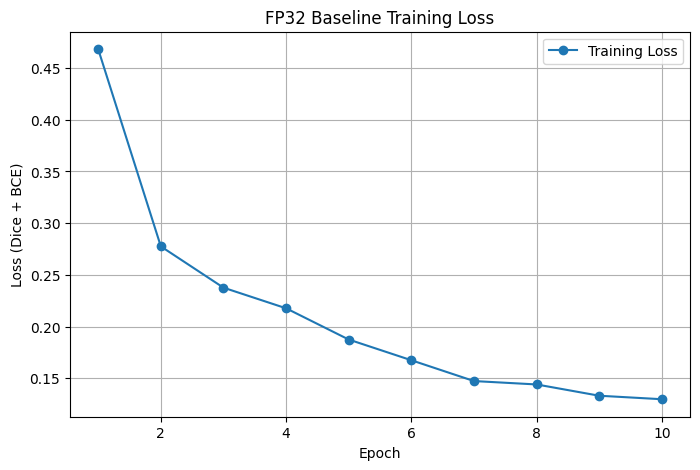

In [4]:
from tqdm import tqdm
from torch.cuda.amp import GradScaler, autocast
import matplotlib.pyplot as plt

num_epochs = 10 
scaler = GradScaler()
epoch_losses = [] 

print("Starting FP32 Baseline Training...")

for epoch in range(num_epochs):
    model.train()
    train_loss = 0.0
    
    # Using the new train_loader
    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs}")
    for images, masks in pbar:
        images = images.to(device)
        masks = masks.to(device)
        
        optimizer.zero_grad()
        
        with autocast():
            outputs = model(images)
            loss = criterion(outputs, masks)
            
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        
        train_loss += loss.item()
        pbar.set_postfix({"Batch Loss": f"{loss.item():.4f}"})
        
    epoch_loss = train_loss / len(train_loader)
    epoch_losses.append(epoch_loss)
    print(f"Epoch {epoch+1} Summary | Average Loss: {epoch_loss:.4f}\n")

# Generate and save the loss graph for the PDF deliverable
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), epoch_losses, marker='o', label='Training Loss')
plt.title('FP32 Baseline Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss (Dice + BCE)')
plt.grid(True)
plt.legend()
plt.savefig("/kaggle/working/training_loss_curve.png")
plt.show()

### **FP32 Model Checkpoint Saving**

Saves the trained model’s learned weights as a `.pth` checkpoint in Kaggle’s working directory for later evaluation or quantization.

In [5]:
import torch

# Define the save path in Kaggle's working directory
save_path = "/kaggle/working/fp32_mobilenetv3_unet_baseline.pth"

# Save only the learned weights
torch.save(model.state_dict(), save_path)
print(f"Model weights successfully saved to {save_path}")

Model weights successfully saved to /kaggle/working/fp32_mobilenetv3_unet_baseline.pth


### **Baseline Uncertainty and Calibration Evaluation**

Evaluates the FP32 model on 15 batches using Dice score, predictive entropy, and Expected Calibration Error (ECE).

In [6]:
import torch.nn.functional as F
import os

def calculate_dice(probs, targets, smooth=1e-5):
    preds = (probs > 0.5).float()
    intersection = (preds * targets).sum()
    union = preds.sum() + targets.sum()
    return (2. * intersection + smooth) / (union + smooth)

def calculate_entropy(probs):
    p = torch.clamp(probs, 1e-7, 1.0 - 1e-7)
    entropy = - (p * torch.log2(p) + (1 - p) * torch.log2(1 - p))
    return entropy.mean().item()

def calculate_ece(probs, targets, n_bins=10):
    bin_boundaries = torch.linspace(0, 1, n_bins + 1).to(probs.device)
    ece = 0.0
    for i in range(n_bins):
        bin_low, bin_high = bin_boundaries[i], bin_boundaries[i+1]
        in_bin = (probs >= bin_low) & (probs < bin_high)
        prop_in_bin = in_bin.float().mean()
        if prop_in_bin > 0:
            accuracy_in_bin = targets[in_bin].float().mean()
            avg_confidence_in_bin = probs[in_bin].mean()
            ece += torch.abs(avg_confidence_in_bin - accuracy_in_bin) * prop_in_bin
    return ece.item()

print("Calculating Preliminary Uncertainty Metrics...")

model.eval()
total_dice, total_entropy, total_ece = 0.0, 0.0, 0.0

with torch.no_grad():
    # CORRECTED: Iterating over val_loader instead of loader
    for images, masks in val_loader:
        images = images.to(device)
        masks = masks.to(device)
        
        logits = model(images)
        probs = torch.sigmoid(logits) 
        
        total_dice += calculate_dice(probs, masks).item()
        total_entropy += calculate_entropy(probs)
        total_ece += calculate_ece(probs, masks)

avg_dice = total_dice / len(val_loader)
avg_ece = total_ece / len(val_loader)
avg_entropy = total_entropy / len(val_loader)

# Format the results
results_text = (
    "----------------------------------------\n"
    "FP32 BASELINE RESULTS (PHASE 1)\n"
    "----------------------------------------\n"
    f"Segmentation Accuracy (Dice): {avg_dice:.4f}\n"
    f"Expected Calibration Error (ECE): {avg_ece:.4f}\n"
    f"Predictive Entropy: {avg_entropy:.4f}\n"
    "----------------------------------------"
)

# Print to console
print(results_text)

# Save to a text file in the Kaggle working directory
metrics_path = "/kaggle/working/fp32_baseline_metrics.txt"
with open(metrics_path, "w") as f:
    f.write(results_text)

print(f"\nMetrics successfully saved to {metrics_path}")

Calculating Preliminary Uncertainty Metrics...
----------------------------------------
FP32 BASELINE RESULTS (PHASE 1)
----------------------------------------
Segmentation Accuracy (Dice): 0.9131
Expected Calibration Error (ECE): 0.0247
Predictive Entropy: 0.0526
----------------------------------------

Metrics successfully saved to /kaggle/working/fp32_baseline_metrics.txt
